# Column spatial-similarity QC

This notebook reads the cached physical-coordinate summary. The expensive pair selection and profile comparisons are performed by `spatial_similarity_qc.py`.

Within each subject, hemisphere, and region, nearby columns are the 20 nearest white-surface anchors. Distant columns are sampled from the farthest 25% of the same region. Distances are computed in physical millimeters after applying the preprocessed DWI transform. Only valid cleaned MD profiles are used.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
QC_ROOT = Path('/mnt/newStor/paros/paros_WORK/xintong/results/spatial_similarity_qc')
SUMMARY = QC_ROOT / 'spatial_similarity_group_summary.csv'
if not SUMMARY.is_file():
    raise FileNotFoundError(f'Run validation/spatial_data/spatial_similarity_qc.py first: {SUMMARY}')
summary = pd.read_csv(SUMMARY)
print(f'Groups: {len(summary):,}; subjects: {summary.subject.nunique():,}')

Groups: 20,317; subjects: 300


## Pair-sampling QC from existing results

These plots use the completed summary and require no new computation. They verify that nearby and distant pairs occupy distinct physical-distance scales.


In [ ]:
near=summary.nearest_mean_distance_mm.dropna()
far=summary.distant_mean_distance_mm.dropna()
ratio=far.to_numpy()/near.to_numpy()
valid_regions=summary.groupby('subject').size()
fig,axes=plt.subplots(1,4,figsize=(20,4))
axes[0].boxplot([near,far],tick_labels=['Nearby','Distant']); axes[0].set_yscale('log'); axes[0].set(title=f'Pair distance separation\nmedian {near.median():.2f} vs {far.median():.2f} mm',ylabel='Distance (mm, log scale)')
axes[1].hist(ratio,bins=50); axes[1].axvline(np.median(ratio),color='crimson',ls='--',label=f'Median {np.median(ratio):.1f}x'); axes[1].set(title='Distant / nearby distance ratio',xlabel='Distance ratio',ylabel='Groups'); axes[1].legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
axes[2].hist(summary.n_columns.dropna(),bins=50); axes[2].set_xscale('log'); axes[2].set(title=f'Usable columns per group\nmedian {summary.n_columns.median():.0f}',xlabel='Columns (log scale)',ylabel='Groups')
axes[3].scatter(range(len(valid_regions)),valid_regions,s=12); axes[3].axhline(68,color='gray',ls='--',label='68 regions'); axes[3].set(title='Valid regions per subject',xlabel='Subjects (sorted ID)',ylabel='Valid regions'); axes[3].set_xticks([]); axes[3].legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
fig.tight_layout(); fig.savefig(QC_ROOT/'pair_sampling_qc_existing_results.png',dpi=180); plt.show()
display(pd.DataFrame({'median_nearby_distance_mm':[near.median()],'median_distant_distance_mm':[far.median()],'median_distance_ratio':[np.median(ratio)],'groups_distant_over_2x_nearby_pct':[100*np.mean(ratio>2)],'median_usable_columns':[summary.n_columns.median()],'subjects_with_68_valid_regions':[int((valid_regions==68).sum())],'total_subjects':[len(valid_regions)]}))


## Cohort comparison

Higher nearby correlation and lower nearby RMSE support spatially structured column profiles within regions.

,profile_corr,profile_rmse,mean_distance_mm
nearest_20,0.936146,0.000101,1.454814
distant_20,0.836073,0.000201,26.490743


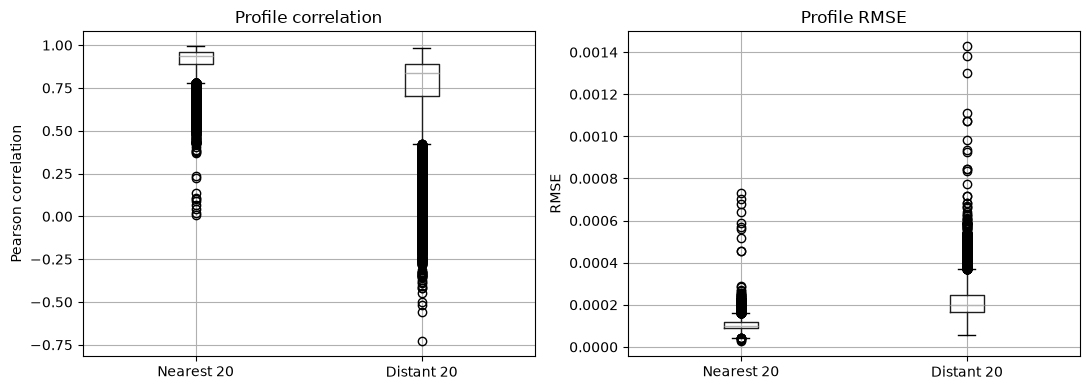

In [6]:
metrics = pd.DataFrame({
    'profile_corr': [summary.nearest_profile_corr.median(), summary.distant_profile_corr.median()],
    'profile_rmse': [summary.nearest_profile_rmse.median(), summary.distant_profile_rmse.median()],
    'mean_distance_mm': [summary.nearest_mean_distance_mm.median(), summary.distant_mean_distance_mm.median()]
}, index=['nearest_20','distant_20'])
display(metrics)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].boxplot([summary.nearest_profile_corr.dropna(),summary.distant_profile_corr.dropna()],tick_labels=['Nearest 20','Distant 20'])
axes[0].set(title='Profile correlation', ylabel='Pearson correlation')
axes[1].boxplot([summary.nearest_profile_rmse.dropna(),summary.distant_profile_rmse.dropna()],tick_labels=['Nearest 20','Distant 20'])
axes[1].set(title='Profile RMSE', ylabel='RMSE')
fig.tight_layout(); fig.savefig(QC_ROOT/'cohort_spatial_similarity.png', dpi=180); plt.show()

## Region and subject effects from existing results

These summaries show whether the nearby correlation advantage is region-specific or driven by a small number of subjects.


In [ ]:
region=summary.groupby(['hemisphere','region'],as_index=False).delta_r.median()
pivot=region.pivot(index='region',columns='hemisphere',values='delta_r').sort_values(['lh','rh'],na_position='last')
subject_effect=summary.groupby('subject',as_index=False).delta_r.median().sort_values('delta_r')
limit=np.nanpercentile(np.abs(pivot.to_numpy()),95)
fig,axes=plt.subplots(1,2,figsize=(15,max(5,.24*len(pivot))))
im=axes[0].imshow(pivot.to_numpy(),aspect='auto',cmap='coolwarm',vmin=-limit,vmax=limit)
axes[0].set(title='Median nearby correlation advantage',xlabel='Hemisphere',ylabel='Region',xticks=range(len(pivot.columns)),xticklabels=pivot.columns,yticks=range(len(pivot.index)),yticklabels=pivot.index)
fig.colorbar(im,ax=axes[0],label='Nearby - distant correlation')
axes[1].scatter(range(len(subject_effect)),subject_effect.delta_r,s=18); axes[1].axhline(0,color='gray',ls='--'); axes[1].set(title='Subject-level median correlation advantage',xlabel='Subjects (sorted)',ylabel='Median nearby - distant correlation'); axes[1].set_xticks([])
fig.tight_layout(); fig.savefig(QC_ROOT/'region_subject_effects_existing_results.png',dpi=180); plt.show()
